In [1]:
import argparse
import pickle
import os
import numpy as np

os.makedirs('figures', exist_ok=True)

## Summarize simulation results for kernel selection (Figure S1)

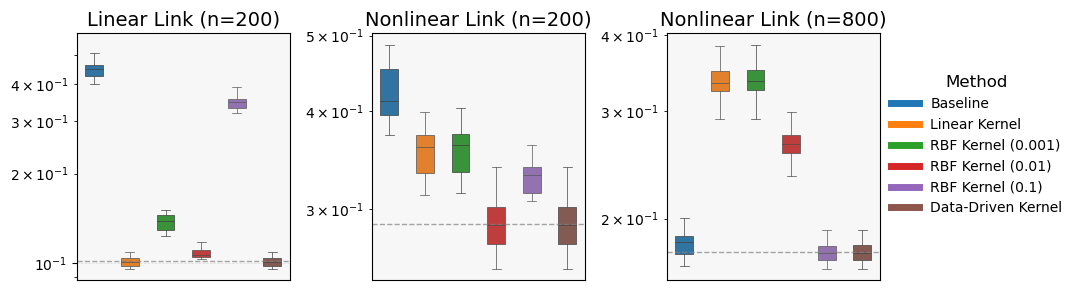

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

p = 4000

data_kernels = ['linear (200)', 'nonlinear (200)', 'nonlinear (800)']
all_data = []
for data_kernel_str in data_kernels:
    data_kernel = data_kernel_str.split(' ')[0]
    n = int(data_kernel_str.split(' ')[1].replace('(', '').replace(')', ''))
    output_dir = f"./results_kernel_selection_data_{data_kernel}"

    # Load all replication results
    replication_files = [os.path.join(output_dir, f) for f in os.listdir(output_dir) if f.startswith(f'data_{data_kernel}_n_{n}_')]
    all_results = []
    for file in replication_files:
        with open(file, 'rb') as f:
            all_results.append(pickle.load(f))


    # Initialize a DataFrame to store all results for easier visualization
    data = []

    # Gather data across replications
    for result in all_results:
        error_baseline = result['error_baseline']
        error_selected = result['error_selected']
        error_kf = result['error_kf']
        
        # Baseline errors 
        data.append({
            'data_kernel': data_kernel,
            'n': n,
            'Replication': result['seed'],
            'q': p,
            'Method': 'Baseline',
            'error_U': error_baseline['error_U'],
            'error_V': error_baseline['error_V'],
            'error_Theta': error_baseline['error_Theta']
        })
    
        # optimal kernel errors 
        data.append({
            'data_kernel': data_kernel,
            'n': n,
            'Replication': result['seed'],
            'q': error_selected['q'],
            'Method': 'Data-driven',
            'error_U': error_selected['error_U_kf'],
            'error_V': error_selected['error_V_kf'],
            'error_Theta': error_selected['error_Theta_kf']
        })

        # Kernel-fused errors
        for kernel, errors in error_kf.items():
            data.append({
                'data_kernel': data_kernel,
                'n': n,
                'Replication': result['seed'],
                'q': errors['q'],
                'Method': kernel,
                'error_U': errors['error_U_kf'],
                'error_V': errors['error_V_kf'],
                'error_Theta': errors['error_Theta_kf']
            })

    all_data.extend(data)

# Convert data to a DataFrame
df1 = pd.DataFrame(all_data)

# Group by method, seed and keep row with the smallest error_Theta
df1 = df1.sort_values('error_Theta').groupby(['data_kernel','n','Method', 'Replication']).first().reset_index()

method_groups = {
    'Baseline': 'Baseline',
    'linear': 'Linear Kernel',
    'rbf1': 'RBF Kernels',
    'rbf2': 'RBF Kernels',
    'rbf3': 'RBF Kernels',
    'Data-driven': 'Data-Driven'
}

df1['Method_Group'] = df1['Method'].map(method_groups)

# Define the desired order of Method_Group
desired_order = ['Baseline', 'Linear Kernel', 'RBF Kernels', 'Data-Driven']  # Replace with your preferred order

# Set the order and sort the DataFrame
df1['Method_Group'] = pd.Categorical(df1['Method_Group'], categories=desired_order, ordered=True)
df1 = df1.sort_values(by=['data_kernel', 'n', 'Method_Group', 'Method'])

# Unique method groups and their base positions
method_groups = df1['Method_Group'].unique()
group_positions = np.array([0.0, 2.5, 5.0, 7.0]) # Base positions for groups on the x-axis
width = 0.4  # Maximum width for spacing methods within each group

# Assign unique colors to each method
unique_methods = df1['Method'].unique()
# fill_palette = sns.color_palette("Spectral", len(unique_methods))
fill_palette = sns.color_palette()
border_palette = [tuple(max(0, x - 0.2) for x in color) for color in fill_palette]

# Map methods to colors
fill_colors = dict(zip(unique_methods, fill_palette))
border_colors = dict(zip(unique_methods, border_palette))



# metrics = ['error_U', 'error_V', 'error_Theta']
metrics = ['error_Theta']
data_kernels = ['linear (200)', 'nonlinear (200)', 'nonlinear (800)']
titles = ['Linear Link (n=200)', 'Nonlinear Link (n=200)', 'Nonlinear Link (n=800)']

for metric in metrics:
    # Create a 2x2 grid with the last plot being the legend
    fig, axes = plt.subplots(1, 3, figsize=(9, 3))
    axes = axes.flatten()

    for i, data_kernel_str in enumerate(data_kernels):
        data_kernel = data_kernel_str.split(' ')[0]
        n = int(data_kernel_str.split(' ')[1].replace('(', '').replace(')', ''))
        ax = axes[i]
        df = df1[(df1['data_kernel'] == data_kernel) & (df1['n'] == n)]
        # Set a background color
        ax.set_facecolor('#f7f7f7')  # Light gray background
        # Add grid lines for a light grid background
        ax.grid(color='lightgray', linestyle='--', linewidth=0.5, alpha=0.7, axis='both')
        
        # Initialize a mapping for custom x-axis positions
        positions = []

        # Calculate custom positions for each group
        for j, group in enumerate(method_groups):
            methods_in_group = df[df['Method_Group'] == group]['Method'].unique()
            n_methods = len(methods_in_group)
            offsets = np.linspace(-width / 2, width / 2, n_methods)  # Evenly space methods in the group
            for k, method in enumerate(methods_in_group):
                positions.append({
                    'group': group,
                    'method': method,
                    'x_position': group_positions[j] + 2 * offsets[k]
                })
        
        # Create a DataFrame for mapping positions
        position_df = pd.DataFrame(positions)

        # Merge custom positions with the original DataFrame
        df_merged = df.merge(position_df, left_on=['Method_Group', 'Method'], right_on=['group', 'method'])

        # Plot boxplots at custom positions
        for method in df_merged['Method'].unique():
            subset = df_merged[df_merged['Method'] == method]
            sns.boxplot(
                x=subset['x_position'],
                y=subset[metric],
                ax=ax,
                width=0.5,
                linewidth=0.5,
                color=fill_colors[method],
                fliersize=0  # Hide outliers for clarity
            )
        # Add horizontal reference line
        mean_data_driven = df[df['Method'] == 'Data-driven'][metric].mean()

        ax.axhline(y=mean_data_driven, color='gray', linestyle='--', linewidth=1, alpha=0.7)

        ax.set_xticks([])
        # ax.set_xticklabels(desired_order, fontsize=8)
        ax.set_title(titles[i], fontsize=14)
        ax.set_yscale('log')
        ax.set_ylabel('')
        ax.set_xlabel('')

    # Custom x-tick labels
    custom_labels = {
        'Baseline': 'Baseline',
        'Data-driven': 'Data-Driven Kernel',
        'linear': 'Linear Kernel',
        'rbf1': 'RBF Kernel (0.001)',
        'rbf2': 'RBF Kernel (0.01)',
        'rbf3': 'RBF Kernel (0.1)'
    }
    # Add shared legend in the bottom-right corner (2,2 subplot)
    legend_handles = [plt.Line2D([0], [0], color=color, lw=5, label=custom_labels[method]) for method, color in fill_colors.items()]

    
    
    fig.legend(
        handles=legend_handles,
        title='Method',
        fontsize=10,
        title_fontsize=12,
        loc='right',
        ncol=1,  # Adjust number of columns as needed
        bbox_to_anchor=(1.2, 0.5),
        # mode='expand',
        frameon=False
    )

    plt.tight_layout()
    plt.savefig(f'./figures/kernel_selection_combined_{metric}.png', dpi=300, bbox_inches='tight')
    # plt.show()

## Summarize results for varying n (Figure 1(a))

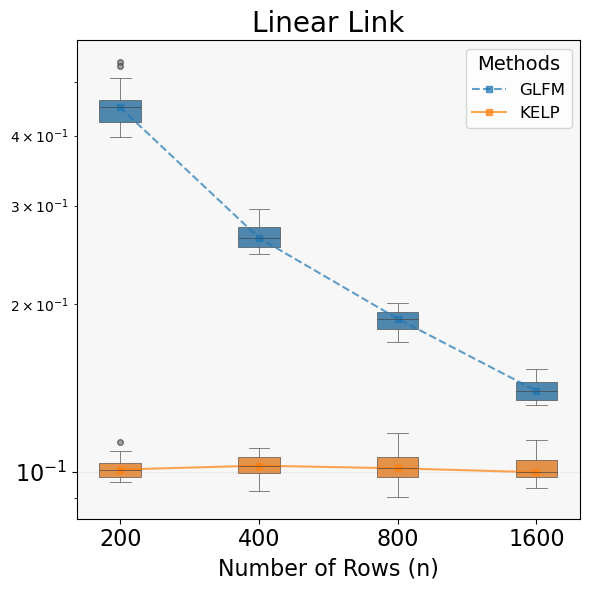

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

data_kernel = 'linear'
titles = {
    'linear': 'Linear Link',
    'nonlinear': 'Nonlinear Link'
}

output_dir = f"./results_n_data_{data_kernel}"

# Load all replication results
replication_files = [os.path.join(output_dir, f) for f in os.listdir(output_dir) if f.startswith(f'data_{data_kernel}')]
all_results = []
for file in replication_files:
    with open(file, 'rb') as f:
        all_results.append(pickle.load(f))

# Initialize a DataFrame to store all results for easier visualization
data = []

# Gather data across replications
for result in all_results:
    error_baseline = result['error_baseline']
    error_selected = result['error_selected']
    
    # Baseline errors 
    for n, error in error_baseline.items():
        data.append({
            'Replication': result['seed'],
            'n': n,
            'Method': 'Baseline',
            'error_U': error['error_U'],
            'error_V': error['error_V'],
            'error_Theta': error['error_Theta']
        })

    # optimal kernel errors 
    for n, error in error_selected.items():
        data.append({
            'Replication': result['seed'],
            'n': n,
            'kernel': error['kernel'],
            'q': error['q'],
            'Method': 'Data-driven',
            'error_U': error['error_U_kf'],
            'error_V': error['error_V_kf'],
            'error_Theta': error['error_Theta_kf']
        })

# Convert data to a DataFrame
df = pd.DataFrame(data)

# Plotting function for all metrics in one plot
def plot_combined_error_boxplots(metric, title):
    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111)  # Add an axes to the figure
    ax.set_facecolor('#f7f7f7')
    
    # Add grid lines for a light grid background
    ax.grid(color='lightgray', linestyle='--', linewidth=0.5, alpha=0.7, axis='both')
    
    # Customize flier properties (outlier points)
    flierprops = {
        'marker': 'o',
        'markersize': 4,  # Reduce the size of outlier points
        'markerfacecolor': 'gray',
        'alpha': 0.7  # Optional: Adjust transparency
    }
    
    # Create a combined boxplot
    sns.boxplot(
        data=df,
        x='n',
        y=metric,
        hue='Method',
        dodge=False,
        palette='tab10',
        width = 0.3,
        linewidth=0.5,
        flierprops=flierprops,
        boxprops=dict(alpha=0.85),  # Adjust alpha here for transparency
        medianprops=dict(alpha=0.9),
        whiskerprops=dict(alpha=0.9),
        capprops=dict(alpha=0.9)
    )
    # Custom x-tick labels
    custom_labels = {
        'Baseline': 'GLFM',
        'Data-driven': 'KELP'
    }

    line_styles = {
        'Baseline': '--',
        'Data-driven': '-',
        # Add more methods if needed
    }
    
    # Calculate medians for each group
    median_data = (
        df.groupby(['n', 'Method'])[metric]
        .median()
        .reset_index()
    )

    # Plot lines connecting the medians
    line_handles = []  # To store line handles for the legend
    for method in median_data['Method'].unique():
        method_data = median_data[median_data['Method'] == method]
        xs = np.array([0,1,2,3])  # Use the same positions as the boxplot
        ys = method_data[metric]
        line, = plt.plot(
            xs,
            ys,
            marker='s',
            linestyle=line_styles.get(method, '-'),
            label=custom_labels.get(method, method),
            alpha=0.7,
            markersize=4 
        )
        line_handles.append(line) 

    # Rename x-ticks
    # handles, labels = plt.gca().get_legend_handles_labels()
    # new_labels = [custom_labels.get(label, label) for label in labels]
    plt.legend(handles=line_handles, title="Methods", fontsize=12, title_fontsize=14, loc='upper right')
    

    # Adjust the plot aesthetics
    plt.title(title, fontsize=20)
    plt.xlabel('Number of Rows (n)', fontsize=16)
    plt.ylabel('', fontsize=16)
    plt.yscale('log')  # Use log scale for better visibility
    # plt.xticks(rotation=45, fontsize=16)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    # plt.legend(title='Method', loc='upper left', fontsize=12, title_fontsize=14)
    plt.tight_layout()
    # plt.show()

    # save to high resolution figures
    plt.savefig(f'./figures/varying_n_{metric}_error_{data_kernel}.png', dpi=300)


# Plot the metrics
# plot_combined_error_boxplots('error_U', f'Relative Error for U')
# plot_combined_error_boxplots('error_V', f'Relative Error for V')
plot_combined_error_boxplots('error_Theta', titles[data_kernel])



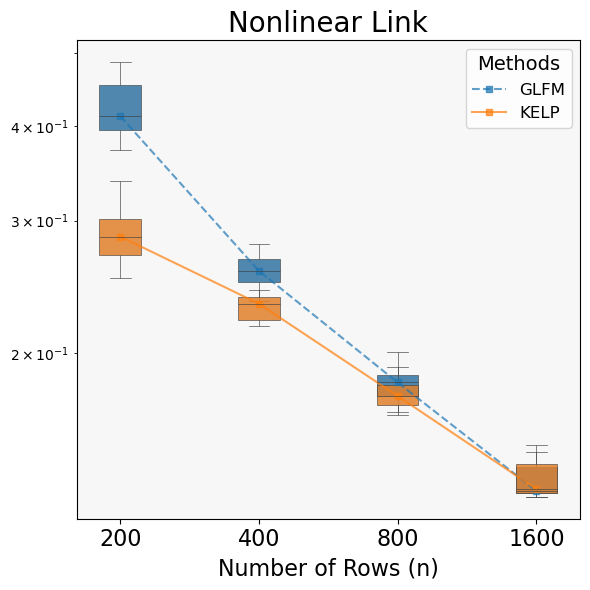

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

data_kernel = 'nonlinear'
titles = {
    'linear': 'Linear Link',
    'nonlinear': 'Nonlinear Link'
}

output_dir = f"./results_n_data_{data_kernel}"

# Load all replication results
replication_files = [os.path.join(output_dir, f) for f in os.listdir(output_dir) if f.startswith(f'data_{data_kernel}')]
all_results = []
for file in replication_files:
    with open(file, 'rb') as f:
        all_results.append(pickle.load(f))

# Initialize a DataFrame to store all results for easier visualization
data = []

# Gather data across replications
for result in all_results:
    error_baseline = result['error_baseline']
    error_selected = result['error_selected']
    
    # Baseline errors 
    for n, error in error_baseline.items():
        data.append({
            'Replication': result['seed'],
            'n': n,
            'Method': 'Baseline',
            'error_U': error['error_U'],
            'error_V': error['error_V'],
            'error_Theta': error['error_Theta']
        })

    # optimal kernel errors 
    for n, error in error_selected.items():
        data.append({
            'Replication': result['seed'],
            'n': n,
            'kernel': error['kernel'],
            'q': error['q'],
            'Method': 'Data-driven',
            'error_U': error['error_U_kf'],
            'error_V': error['error_V_kf'],
            'error_Theta': error['error_Theta_kf']
        })

# Convert data to a DataFrame
df = pd.DataFrame(data)

# Plotting function for all metrics in one plot
def plot_combined_error_boxplots(metric, title):
    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111)  # Add an axes to the figure
    ax.set_facecolor('#f7f7f7')
    
    # Add grid lines for a light grid background
    ax.grid(color='lightgray', linestyle='--', linewidth=0.5, alpha=0.7, axis='both')
    
    # Customize flier properties (outlier points)
    flierprops = {
        'marker': 'o',
        'markersize': 4,  # Reduce the size of outlier points
        'markerfacecolor': 'gray',
        'alpha': 0.7  # Optional: Adjust transparency
    }
    
    # Create a combined boxplot
    sns.boxplot(
        data=df,
        x='n',
        y=metric,
        hue='Method',
        dodge=False,
        palette='tab10',
        width = 0.3,
        linewidth=0.5,
        flierprops=flierprops,
        boxprops=dict(alpha=0.85),  # Adjust alpha here for transparency
        medianprops=dict(alpha=0.9),
        whiskerprops=dict(alpha=0.9),
        capprops=dict(alpha=0.9)
    )
    # Custom x-tick labels
    custom_labels = {
        'Baseline': 'GLFM',
        'Data-driven': 'KELP'
    }

    line_styles = {
        'Baseline': '--',
        'Data-driven': '-',
        # Add more methods if needed
    }
    
    # Calculate medians for each group
    median_data = (
        df.groupby(['n', 'Method'])[metric]
        .median()
        .reset_index()
    )

    # Plot lines connecting the medians
    line_handles = []  # To store line handles for the legend
    for method in median_data['Method'].unique():
        method_data = median_data[median_data['Method'] == method]
        xs = np.array([0,1,2,3])  # Use the same positions as the boxplot
        ys = method_data[metric]
        line, = plt.plot(
            xs,
            ys,
            marker='s',
            linestyle=line_styles.get(method, '-'),
            label=custom_labels.get(method, method),
            alpha=0.7,
            markersize=4 
        )
        line_handles.append(line) 

    # Rename x-ticks
    # handles, labels = plt.gca().get_legend_handles_labels()
    # new_labels = [custom_labels.get(label, label) for label in labels]
    plt.legend(handles=line_handles, title="Methods", fontsize=12, title_fontsize=14, loc='upper right')
    

    # Adjust the plot aesthetics
    plt.title(title, fontsize=20)
    plt.xlabel('Number of Rows (n)', fontsize=16)
    plt.ylabel('', fontsize=16)
    plt.yscale('log')  # Use log scale for better visibility
    # plt.xticks(rotation=45, fontsize=16)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    # plt.legend(title='Method', loc='upper left', fontsize=12, title_fontsize=14)
    plt.tight_layout()
    # plt.show()

    # save to high resolution figures
    plt.savefig(f'./figures/varying_n_{metric}_error_{data_kernel}.png', dpi=300)


# Plot the metrics
# plot_combined_error_boxplots('error_U', f'Relative Error for U')
# plot_combined_error_boxplots('error_V', f'Relative Error for V')
plot_combined_error_boxplots('error_Theta', titles[data_kernel])



# Summarize results for varying p (Figure 1(b))

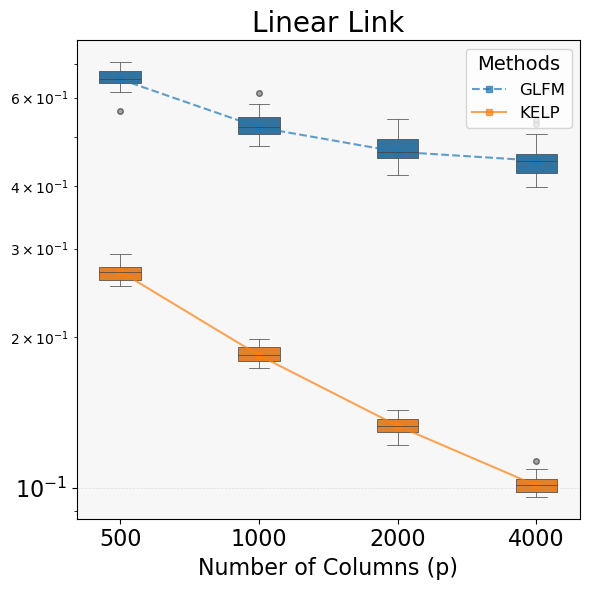

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
# plt.rcParams['text.usetex'] = True
# plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'

data_kernel = 'linear'
titles = {  
    'linear': 'Linear Link',
    'nonlinear': 'Nonlinear Link'
}
output_dir = f"./results_p_data_{data_kernel}"

# Load all replication results
replication_files = [os.path.join(output_dir, f) for f in os.listdir(output_dir) if f.startswith(f'data_{data_kernel}')]
all_results = []
for file in replication_files:
    with open(file, 'rb') as f:
        all_results.append(pickle.load(f))

# Initialize a DataFrame to store all results for easier visualization
data = []

# Gather data across replications
for result in all_results:
    error_baseline = result['error_baseline']
    error_selected = result['error_selected']
    
    # Baseline errors 
    for p, error in error_baseline.items():
        data.append({
            'Replication': result['seed'],
            'p': p,
            'Method': 'Baseline',
            'error_U': error['error_U'],
            'error_V': error['error_V'],
            'error_Theta': error['error_Theta']
        })

    # optimal kernel errors 
    for p, error in error_selected.items():
        data.append({
            'Replication': result['seed'],
            'p': p,
            'kernel': error['kernel'],
            'q': error['q'],
            'Method': 'Data-driven',
            'error_U': error['error_U_kf'],
            'error_V': error['error_V_kf'],
            'error_Theta': error['error_Theta_kf']
        })

# Convert data to a DataFrame
df = pd.DataFrame(data)
df = df[df['p'] <=4000]

# Plotting function for all metrics in one plot
def plot_combined_error_boxplots(metric, title):
    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111)  # Add an axes to the figure
    ax.set_facecolor('#f7f7f7')

    # Add grid lines for a light grid background
    ax.grid(color='lightgray', linestyle='--', linewidth=0.5, alpha=0.7, axis='both')
    
    # Customize flier properties (outlier points)
    flierprops = {
        'marker': 'o',
        'markersize': 4,  # Reduce the size of outlier points
        'markerfacecolor': 'gray',
        'alpha': 0.7  # Optional: Adjust transparency
    }
    
    # Create a combined boxplot
    sns.boxplot(
        data=df,
        x='p',
        y=metric,
        hue='Method',
        dodge=False,
        palette='tab10',
        width = 0.3,
        linewidth=0.5,
        flierprops=flierprops
    )
    # Custom x-tick labels
    custom_labels = {
        'Baseline': 'GLFM',
        'Data-driven': 'KELP'
    }
    
    line_styles = {
        'Baseline': '--',
        'Data-driven': '-',
        # Add more methods if needed
    }
    
    # Calculate medians for each group
    median_data = (
        df.groupby(['p', 'Method'])[metric]
        .median()
        .reset_index()
    )

    # Plot lines connecting the medians
    line_handles = []  # To store line handles for the legend
    for method in median_data['Method'].unique():
        method_data = median_data[median_data['Method'] == method]
        xs = np.array([0,1,2,3])  # Use the same positions as the boxplot
        ys = method_data[metric]
        line, = plt.plot(
            xs,
            ys,
            marker='s',
            linestyle=line_styles.get(method, '-'),
            label=custom_labels.get(method, method),
            alpha=0.7,
            markersize=4 
        )
        line_handles.append(line) 

    # Rename x-ticks
    # handles, labels = plt.gca().get_legend_handles_labels()
    # new_labels = [custom_labels.get(label, label) for label in labels]
    plt.legend(handles=line_handles, title="Methods", fontsize=12, title_fontsize=14, loc='upper right')
    

    # Adjust the plot aesthetics
    plt.title(title, fontsize=20)
    plt.xlabel('Number of Columns (p)', fontsize=16)
    plt.ylabel('', fontsize=16)
    plt.yscale('log')  # Use log scale for better visibility
    # plt.ylim(0.2, 0.8)
    # plt.xticks(rotation=45, fontsize=16)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    # plt.legend(title='Method', loc='upper left', fontsize=12, title_fontsize=14)
    plt.tight_layout()
    # plt.show()

    # save to high resolution figures
    plt.savefig(f'./figures/varying_p_{metric}_error_{data_kernel}.png', dpi=300)


# Plot the metrics
plot_combined_error_boxplots('error_Theta', titles[data_kernel])



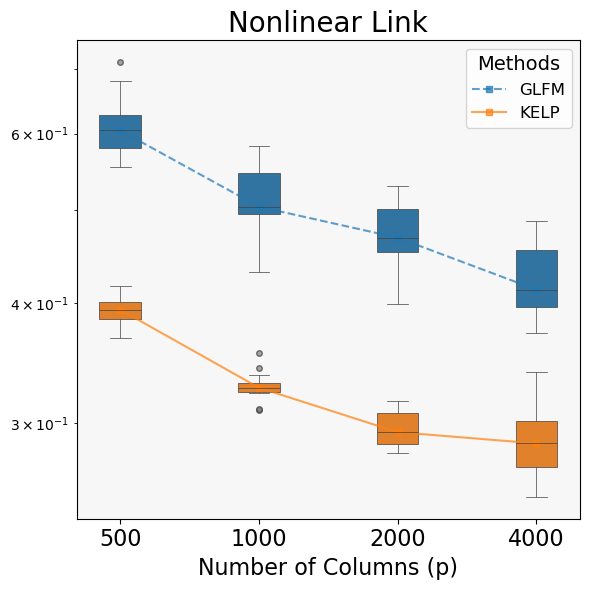

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
# plt.rcParams['text.usetex'] = True
# plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'

data_kernel = 'nonlinear'
titles = {  
    'linear': 'Linear Link',
    'nonlinear': 'Nonlinear Link'
}
output_dir = f"./results_p_data_{data_kernel}"

# Load all replication results
replication_files = [os.path.join(output_dir, f) for f in os.listdir(output_dir) if f.startswith(f'data_{data_kernel}')]
all_results = []
for file in replication_files:
    with open(file, 'rb') as f:
        all_results.append(pickle.load(f))

# Initialize a DataFrame to store all results for easier visualization
data = []

# Gather data across replications
for result in all_results:
    error_baseline = result['error_baseline']
    error_selected = result['error_selected']
    
    # Baseline errors 
    for p, error in error_baseline.items():
        data.append({
            'Replication': result['seed'],
            'p': p,
            'Method': 'Baseline',
            'error_U': error['error_U'],
            'error_V': error['error_V'],
            'error_Theta': error['error_Theta']
        })

    # optimal kernel errors 
    for p, error in error_selected.items():
        data.append({
            'Replication': result['seed'],
            'p': p,
            'kernel': error['kernel'],
            'q': error['q'],
            'Method': 'Data-driven',
            'error_U': error['error_U_kf'],
            'error_V': error['error_V_kf'],
            'error_Theta': error['error_Theta_kf']
        })

# Convert data to a DataFrame
df = pd.DataFrame(data)
df = df[df['p'] <=4000]

# Plotting function for all metrics in one plot
def plot_combined_error_boxplots(metric, title):
    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111)  # Add an axes to the figure
    ax.set_facecolor('#f7f7f7')

    # Add grid lines for a light grid background
    ax.grid(color='lightgray', linestyle='--', linewidth=0.5, alpha=0.7, axis='both')
    
    # Customize flier properties (outlier points)
    flierprops = {
        'marker': 'o',
        'markersize': 4,  # Reduce the size of outlier points
        'markerfacecolor': 'gray',
        'alpha': 0.7  # Optional: Adjust transparency
    }
    
    # Create a combined boxplot
    sns.boxplot(
        data=df,
        x='p',
        y=metric,
        hue='Method',
        dodge=False,
        palette='tab10',
        width = 0.3,
        linewidth=0.5,
        flierprops=flierprops
    )
    # Custom x-tick labels
    custom_labels = {
        'Baseline': 'GLFM',
        'Data-driven': 'KELP'
    }
    
    line_styles = {
        'Baseline': '--',
        'Data-driven': '-',
        # Add more methods if needed
    }
    
    # Calculate medians for each group
    median_data = (
        df.groupby(['p', 'Method'])[metric]
        .median()
        .reset_index()
    )

    # Plot lines connecting the medians
    line_handles = []  # To store line handles for the legend
    for method in median_data['Method'].unique():
        method_data = median_data[median_data['Method'] == method]
        xs = np.array([0,1,2,3])  # Use the same positions as the boxplot
        ys = method_data[metric]
        line, = plt.plot(
            xs,
            ys,
            marker='s',
            linestyle=line_styles.get(method, '-'),
            label=custom_labels.get(method, method),
            alpha=0.7,
            markersize=4 
        )
        line_handles.append(line) 

    # Rename x-ticks
    # handles, labels = plt.gca().get_legend_handles_labels()
    # new_labels = [custom_labels.get(label, label) for label in labels]
    plt.legend(handles=line_handles, title="Methods", fontsize=12, title_fontsize=14, loc='upper right')
    

    # Adjust the plot aesthetics
    plt.title(title, fontsize=20)
    plt.xlabel('Number of Columns (p)', fontsize=16)
    plt.ylabel('', fontsize=16)
    plt.yscale('log')  # Use log scale for better visibility
    # plt.ylim(0.2, 0.8)
    # plt.xticks(rotation=45, fontsize=16)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    # plt.legend(title='Method', loc='upper left', fontsize=12, title_fontsize=14)
    plt.tight_layout()
    # plt.show()

    # save to high resolution figures
    plt.savefig(f'./figures/varying_p_{metric}_error_{data_kernel}.png', dpi=300)


# Plot the metrics
plot_combined_error_boxplots('error_Theta', titles[data_kernel])



# Summarize results for varying sparsity level (Figure 1(c))

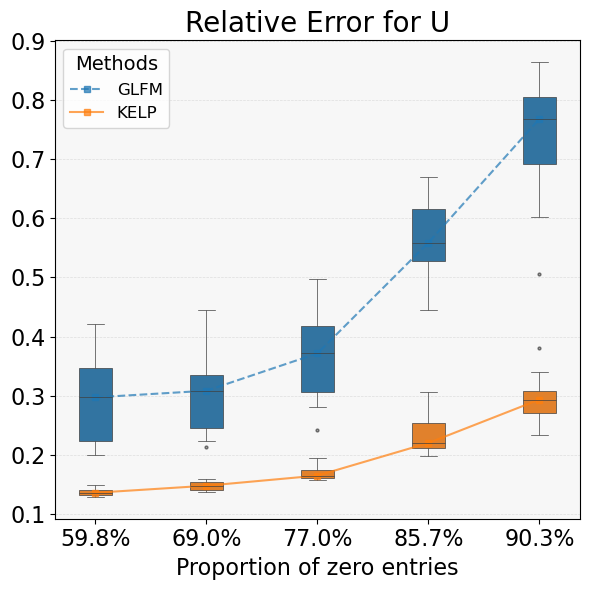

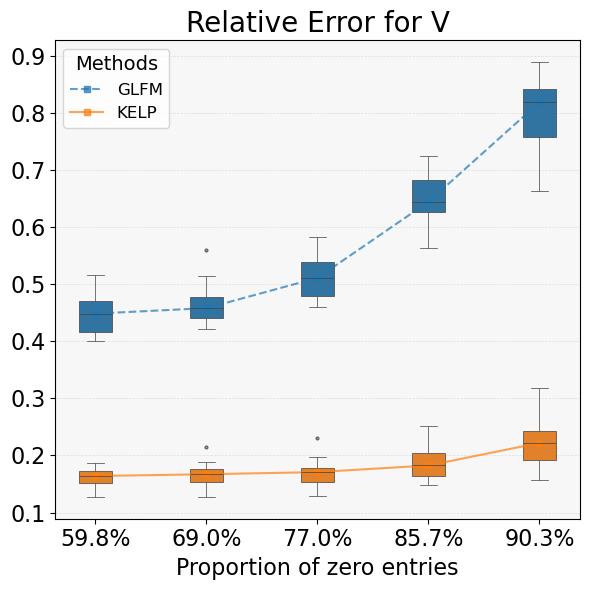

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

data_kernel = 'linear'
output_dir = f"./results_rho_data_{data_kernel}"

# Load all replication results
replication_files = [os.path.join(output_dir, f) for f in os.listdir(output_dir) if f.startswith(f'data_{data_kernel}')]
all_results = []
for file in replication_files:
    with open(file, 'rb') as f:
        all_results.append(pickle.load(f))

# Initialize a DataFrame to store all results for easier visualization
data = []

# Gather data across replications
for result in all_results:
    error_baseline = result['error_baseline']
    error_selected = result['error_selected']
    
    # Baseline errors 
    for rho, error in error_baseline.items():
        data.append({
            'success': error['success'],
            'Replication': result['seed'],
            'sparsity': error['sparsity'],
            'rho': rho,
            'Method': 'Baseline',
            'error_U': error['error_U'],
            'error_V': error['error_V'],
            'error_Theta': error['error_Theta']
        })

    # optimal kernel errors 
    for rho, error in error_selected.items():
        data.append({
            'success': error['success'],
            'Replication': result['seed'],
            'sparsity': error['sparsity'],
            'rho': rho,
            'kernel': error['kernel'],
            'q': error['q'],
            'Method': 'Data-driven',
            'error_U': error['error_U_kf'],
            'error_V': error['error_V_kf'],
            'error_Theta': error['error_Theta_kf']
        })

# Convert data to a DataFrame
df = pd.DataFrame(data)
df = df[df['success'] == True]

df['mean_sparsity'] = 1 - df.groupby(['Method', 'rho'])['sparsity'].transform('mean').round(3)

# Plotting function for all metrics in one plot
def plot_combined_error_boxplots(metric, title):
    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111)  # Add an axes to the figure
    ax.set_facecolor('#f7f7f7')

    # Add grid lines for a light grid background
    ax.grid(color='lightgray', linestyle='--', linewidth=0.5, alpha=0.7, axis='both')
    
    # Customize flier properties (outlier points)
    flierprops = {
        'marker': 'o',
        'markersize': 2,  # Reduce the size of outlier points
        'markerfacecolor': 'gray',
        'alpha': 0.7  # Optional: Adjust transparency
    }
    
    # Create a combined boxplot
    sns.boxplot(
        data=df,
        x='mean_sparsity',
        y=metric,
        hue='Method',
        dodge=False,
        palette='tab10',
        width = 0.3,
        linewidth=0.5,
        flierprops=flierprops
    )
    # Custom x-tick labels
    custom_labels = {
        'Baseline': 'GLFM',
        'Data-driven': 'KELP'
    }
    
    line_styles = {
        'Baseline': '--',
        'Data-driven': '-',
        # Add more methods if needed
    }
    
    # Calculate medians for each group
    median_data = (
        df.groupby(['mean_sparsity', 'Method'])[metric]
        .median()
        .reset_index()
    )

    # Plot lines connecting the medians
    line_handles = []  # To store line handles for the legend
    for method in median_data['Method'].unique():
        method_data = median_data[median_data['Method'] == method]
        xs = np.array([0,1,2,3,4])  # Use the same positions as the boxplot
        ys = method_data[metric]
        line, = plt.plot(
            xs,
            ys,
            marker='s',
            linestyle=line_styles.get(method, '-'),
            label=custom_labels.get(method, method),
            alpha=0.7,
            markersize=4 
        )
        line_handles.append(line) 

    plt.legend(handles=line_handles, title="Methods", fontsize=12, title_fontsize=14, loc='upper left')
    

    # Adjust the plot aesthetics
    plt.title(title, fontsize=20)
    plt.xlabel('Proportion of zero entries', fontsize=16)
    plt.ylabel('', fontsize=16)
    # x ticks only keep three decimal points
    original_xticks = df['mean_sparsity'].unique()
    original_xticks.sort()  # Ensure sorted order
    plt.xticks(
        ticks=range(len(original_xticks)),
        labels=[f'{x * 100:.1f}%' for x in original_xticks],
        fontsize=16
    )
    plt.yticks(fontsize=16)
    plt.tight_layout()
    # plt.show()

    # save to high resolution figures
    plt.savefig(f'./figures/varying_rho_{metric}_error_{data_kernel}.png', dpi=300)


# Plot the metrics
plot_combined_error_boxplots('error_U', f'Relative Error for U')
plot_combined_error_boxplots('error_V', f'Relative Error for V')



# Summarize results for misaligned semantic information (Figure S2)

Results of `simulation_misspec.py`. The column embeddings mix a component orthogonal to the semantic span with proportion $a$. Plots the relative error for $\Theta$ versus $a$ (Figure S2).

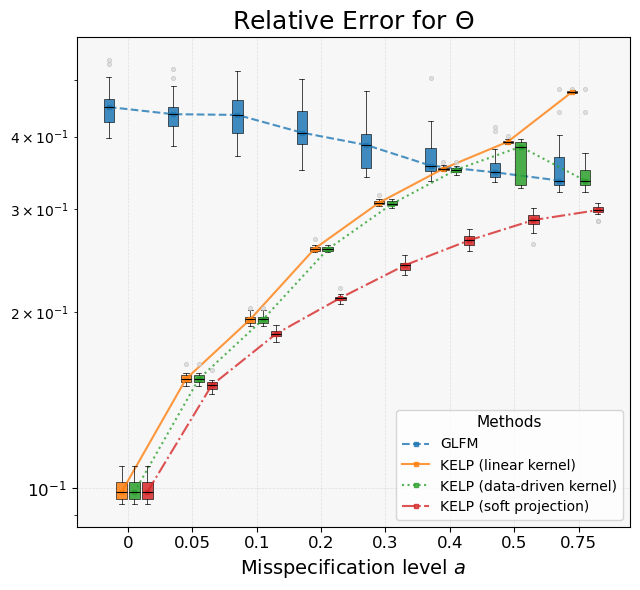

Figure saved to ./figures/misspec_error_Theta_linear.png


In [8]:
import glob
import os
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

result_dir = "./results_misspec_data_linear"
figure_dir = "./figures"

methods = {
    'baseline': 'GLFM',
    'kelp': 'KELP (linear kernel)',
    'selected': 'KELP (data-driven kernel)',
    'soft': 'KELP (soft projection)',
}
colors = dict(zip(methods.values(), plt.get_cmap('tab10').colors))
line_styles = dict(zip(methods.values(), ['--', '-', ':', '-.']))
metric, title = 'error_Theta', r'Relative Error for $\Theta$'

# Load all replication results
rows = []
for file in glob.glob(os.path.join(result_dir, 'misspec_a_*.pkl')):
    with open(file, 'rb') as f:
        result = pickle.load(f)
    for key, name in methods.items():
        rows.append({'a': result['a'], 'seed': result['seed'], 'Method': name,
                     metric: result[key][metric]})
df = pd.DataFrame(rows)
a_values = sorted(df['a'].unique())

# Boxplots with medians connected
def plot_error_boxplots(metric):
    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.set_facecolor('#f7f7f7')
    ax.grid(color='lightgray', linestyle='--', linewidth=0.5, alpha=0.7, axis='both')
    width = 0.8 / len(methods)
    for k, name in enumerate(methods.values()):
        positions = np.arange(len(a_values)) + (k - (len(methods) - 1) / 2) * width
        data = [df[(df['a'] == a) & (df['Method'] == name)][metric].values for a in a_values]
        ax.boxplot(data, positions=positions, widths=width * 0.8, patch_artist=True,
                   boxprops=dict(facecolor=colors[name], alpha=0.85, linewidth=0.5),
                   medianprops=dict(color='black', linewidth=0.8),
                   whiskerprops=dict(linewidth=0.5), capprops=dict(linewidth=0.5),
                   flierprops=dict(marker='o', markersize=3, markerfacecolor='#d9d9d9',
                                   markeredgecolor='#bdbdbd', markeredgewidth=0.5, alpha=0.8))
        ax.plot(positions, [np.median(d) for d in data], marker='s', markersize=3,
                linestyle=line_styles[name], color=colors[name], alpha=0.8, label=name)
    ax.set_xticks(np.arange(len(a_values)))
    ax.set_xticklabels([f'{a:g}' for a in a_values], fontsize=12)
    ax.set_yscale('log')
    ax.tick_params(axis='y', labelsize=12)
    ax.set_xlabel('Misspecification level $a$', fontsize=14)
    ax.set_title(title, fontsize=18)
    ax.legend(title='Methods', fontsize=10, title_fontsize=11, loc='best')
    fig.tight_layout()
    fig.savefig(os.path.join(figure_dir, f'misspec_{metric}_linear.png'), dpi=300)
    plt.show()


os.makedirs(figure_dir, exist_ok=True)
plot_error_boxplots(metric)
print(f'Figure saved to {figure_dir}/misspec_{metric}_linear.png')